# UCS420 Assignment 7 — NLP-I
Roll number: 1024170352  
Name: Rahil


In [ ]:
# Q1
ROLL_NO = 1024170352
NAME = "Rahil"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"


### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
# Q1
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)


Roll number: 1024170396   Name: Harkamal Singh   Fingerprint: D11CC225   Tickets: 13

Ticket_ID                                                                                  Ticket_Text
      T01                                                 Call me on +91 98765 43210 or 0175-239-3201.
      T02                                                    The printer won't print; it isn't jammed.
      T03                                   The laptop is showing an error. Is there another solution?
      T04 I couldn't connect to the Matlab when connected to campus Wi-Fi. I have tried several times!
      T05                                                        I need Windows 11 by 5.30 p.m. today.
      T06                                    Server was working yesterday during the lab. Please help.
      T07                                                   The e-mail is not working. This is urgent.
      T08        I cannot access the server after restarting the system. It works on anoth

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# Q1
from IPython.display import display

processed_tickets = []
rows = []
all_tokens = []

for ticket_id, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    result = process_ticket(text)
    processed_tickets.append(result)
    all_tokens.extend(result["tokens"])
    rows.append({
        "Ticket": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique tokens": len(set(result["tokens"])),
        "Final tokens": len(result["final"])
    })

counts = pd.DataFrame(rows)
totals = counts.drop(columns="Ticket").sum()
totals["Unique tokens"] = len(set(all_tokens))
totals["Ticket"] = "TOTAL"
counts = pd.concat([counts, pd.DataFrame([totals])], ignore_index=True)
display(counts)
print("TOTAL unique tokens counts distinct tokens across all tickets.")

selected_ticket = processed_tickets[0]
print("Selected ticket:", df.loc[0, "Ticket_ID"])
print("Raw text:", df.loc[0, "Ticket_Text"])
print("Tokens:", selected_ticket["tokens"])
print("Punctuation tokens:", selected_ticket["punct"])
print("Stopwords:", selected_ticket["stops"])
print("Final tokens:", selected_ticket["final"])


,Ticket,Sentences,Tokens,Punctuation,Stopwords,Unique tokens,Final tokens
0,T01,1,9,1,3,9,5
1,T02,1,11,2,3,10,6
2,T03,2,12,2,5,11,5
3,T04,2,19,2,7,17,10
4,T05,1,9,1,2,9,6
5,T06,2,11,2,3,10,6
6,T07,2,10,2,5,8,3
7,T08,2,17,2,8,15,7
8,T09,2,9,2,2,8,5
9,T10,2,14,2,5,13,7


TOTAL unique tokens counts distinct tokens across all tickets.
Selected ticket: T01
Raw text: Call me on +91 98765 43210 or 0175-239-3201.
Tokens: ['call', 'me', 'on', '+91', '98765', '43210', 'or', '0175-239-3201', '.']
Punctuation tokens: ['.']
Stopwords: ['me', 'on', 'or']
Final tokens: ['call', '+91', '98765', '43210', '0175-239-3201']


**Observe:** Which final tokens in your data are not real words? Where do they come from?

`n't`, `wo`, and `'s` are fragments. `word_tokenize()` splits contractions such as `won't`, `isn't`, and `couldn't`, and splits the possessive in `Rao's`. The pipeline keeps these fragments because they are neither complete punctuation tokens nor listed stopwords.


---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
# Q2(a)(i)
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

raw_texts = df["Ticket_Text"].tolist() + TEST_LINES
text_labels = df["Ticket_ID"].tolist() + ["TEST 1", "TEST 2", "TEST 3"]

for label, text in zip(text_labels, raw_texts):
    words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    print(label, words)


T01 []
T02 ['printer', 'jammed']
T03 ['laptop', 'showing', 'another', 'solution']
T04 ['couldn', 'connect', 'Matlab', 'connected', 'campus', 'several']
T05 ['Windows']
T06 ['Server', 'working', 'yesterday', 'during', 'Please']
T07 ['working', 'urgent']
T08 ['cannot', 'access', 'server', 'restarting', 'system', 'another', 'computer']
T09 ['crashes', 'opening', 'Please']
T10 ['restarting', 'resetting', 'password', 'Please', 'resolve']
T11 []
T12 ['stopped', 'syncing', 'another', 'computer']
T13 ['Student', 'portal', 'running', 'slowly', 'during', 'Please']
TEST 1 ['helpdesk', 'thapar', 'thapar', 'thapar']
TEST 2 ['Version']
TEST 3 []


In [7]:
# Q2(a)(ii)
number_pattern = r"\b(?:0[xX][0-9A-Fa-f]+|[0-9]+(?:,[0-9]{3})*(?:\.[0-9]+)*)\b"

for label, text in zip(text_labels, raw_texts):
    numbers = re.findall(number_pattern, text)
    print(label, numbers)


T01 ['91', '98765', '43210', '0175', '239', '3201']
T02 []
T03 []
T04 []
T05 ['11', '5.30']
T06 []
T07 []
T08 []
T09 []
T10 []
T11 ['14']
T12 []
T13 []
TEST 1 []
TEST 2 ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
TEST 3 ['5.30']


In [8]:
# Q2(a)(iii)
for label, text in zip(text_labels, raw_texts):
    words = re.findall(r"\b[A-Z][A-Za-z]*\b", text)
    print(label, words)


T01 ['Call']
T02 ['The']
T03 ['The', 'Is']
T04 ['I', 'Matlab', 'Wi', 'Fi', 'I']
T05 ['I', 'Windows']
T06 ['Server', 'Please']
T07 ['The', 'This']
T08 ['I', 'It']
T09 ['The', 'LMS', 'Please']
T10 ['I', 'Please']
T11 ['Dr', 'Rao', 'PC', 'No']
T12 ['The', 'It']
T13 ['Student', 'Please']
TEST 1 ['Mail']
TEST 2 ['Call', 'Version', 'Rs']
TEST 3 ['The']


In [9]:
# Q2(a)(iv)
for label, text in zip(text_labels, raw_texts):
    words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)
    print(label, words)


T01 ['on', 'or']
T02 ['it', 'isn']
T03 ['is', 'an', 'error', 'Is', 'another']
T04 ['I', 'I']
T05 ['I']
T06 []
T07 ['e', 'is', 'is', 'urgent']
T08 ['I', 'access', 'after', 'It', 'on', 'another']
T09 ['opening']
T10 ['I', 'after', 'it']
T11 ['is']
T12 ['e', 'It', 'on', 'another']
T13 ['is']
TEST 1 ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
TEST 2 ['or', 'is']
TEST 3 ['of', 'art', 'isn', 'open', 'in', 'at']


In [10]:
# Q2(b)(i)
email_pattern = r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"

for label, text in zip(text_labels, raw_texts):
    new_text = re.sub(email_pattern, "<EMAIL>", text)
    print(label, new_text)


T01 Call me on +91 98765 43210 or 0175-239-3201.
T02 The printer won't print; it isn't jammed.
T03 The laptop is showing an error. Is there another solution?
T04 I couldn't connect to the Matlab when connected to campus Wi-Fi. I have tried several times!
T05 I need Windows 11 by 5.30 p.m. today.
T06 Server was working yesterday during the lab. Please help.
T07 The e-mail is not working. This is urgent.
T08 I cannot access the server after restarting the system. It works on another computer.
T09 The LMS crashes while opening. Please help.
T10 I tried restarting the wifi after resetting my password. Please resolve it.
T11 Dr. Rao's lab PC (No. 14) is down.
T12 The e-mail has stopped syncing. It works on another computer.
T13 Student portal is running slowly during the lab. Please help.
TEST 1 Mail <EMAIL> or <EMAIL>; visit https://lms.thapar.edu/help or www.thapar.edu/it.
TEST 2 Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
TEST 3 The 

In [11]:
# Q2(b)(ii)
url_pattern = r"(?:https?://|www\.)[^\s<>]*[A-Za-z0-9/#]"

for label, text in zip(text_labels, raw_texts):
    new_text = re.sub(url_pattern, "<URL>", text)
    print(label, new_text)


T01 Call me on +91 98765 43210 or 0175-239-3201.
T02 The printer won't print; it isn't jammed.
T03 The laptop is showing an error. Is there another solution?
T04 I couldn't connect to the Matlab when connected to campus Wi-Fi. I have tried several times!
T05 I need Windows 11 by 5.30 p.m. today.
T06 Server was working yesterday during the lab. Please help.
T07 The e-mail is not working. This is urgent.
T08 I cannot access the server after restarting the system. It works on another computer.
T09 The LMS crashes while opening. Please help.
T10 I tried restarting the wifi after resetting my password. Please resolve it.
T11 Dr. Rao's lab PC (No. 14) is down.
T12 The e-mail has stopped syncing. It works on another computer.
T13 Student portal is running slowly during the lab. Please help.
TEST 1 Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit <URL> or <URL>.
TEST 2 Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
TEST 3 The state

In [12]:
# Q2(b)(iii)
phone_pattern = r"(?<!\w)(?:\+91[ -]?[0-9]{5}[ -]?[0-9]{5}|0[0-9]{3}-[0-9]{3}-[0-9]{4})(?!\w)"

for label, text in zip(text_labels, raw_texts):
    new_text = re.sub(phone_pattern, "<PHONE>", text)
    print(label, new_text)


T01 Call me on <PHONE> or <PHONE>.
T02 The printer won't print; it isn't jammed.
T03 The laptop is showing an error. Is there another solution?
T04 I couldn't connect to the Matlab when connected to campus Wi-Fi. I have tried several times!
T05 I need Windows 11 by 5.30 p.m. today.
T06 Server was working yesterday during the lab. Please help.
T07 The e-mail is not working. This is urgent.
T08 I cannot access the server after restarting the system. It works on another computer.
T09 The LMS crashes while opening. Please help.
T10 I tried restarting the wifi after resetting my password. Please resolve it.
T11 Dr. Rao's lab PC (No. 14) is down.
T12 The e-mail has stopped syncing. It works on another computer.
T13 Student portal is running slowly during the lab. Please help.
TEST 1 Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
TEST 2 Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
TEST 3 The state-o

In [13]:
# Q2(c)
common_start_words = {"Call", "The", "Is", "Server", "Please", "This", "It", "Student"}
capitalized_at_start = []

for text in df["Ticket_Text"]:
    for sentence in sent_tokenize(text):
        words = re.findall(r"\b[A-Z][A-Za-z]*\b", sentence)
        if words and sentence.startswith(words[0]) and words[0] in common_start_words:
            capitalized_at_start.append(words[0])

print("Words capitalized only at the start of a sentence:", capitalized_at_start)
print("Number of occurrences:", len(capitalized_at_start))
print("I, names, titles and acronyms are excluded because they need capitals elsewhere too.")


Words capitalized only at the start of a sentence: ['Call', 'The', 'The', 'Is', 'Server', 'Please', 'The', 'This', 'It', 'The', 'Please', 'Please', 'The', 'It', 'Student', 'Please']
Number of occurrences: 16
I, names, titles and acronyms are excluded because they need capitals elsewhere too.


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

There are 16 occurrences: Call (1), The (5), Is (1), Server (1), Please (4), This (1), It (2), and Student (1). The count excludes I, proper names, acronyms, and titles.


---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [14]:
# Q3(a)
from nltk.tokenize import RegexpTokenizer

word_pattern = r"[A-Za-z]+(?:[-'][A-Za-z]+)*"
token_pattern = (
    email_pattern + "|" + url_pattern + "|" + phone_pattern + "|" +
    number_pattern + "|" + word_pattern + r"|[^\w\s]"
)
custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

for label, text in zip(text_labels, raw_texts):
    print(label)
    print("Custom:", my_tokenize(text))
    print("NLTK:", word_tokenize(text))
    print()


T01
Custom: ['Call', 'me', 'on', '+91 98765 43210', 'or', '0175-239-3201', '.']
NLTK: ['Call', 'me', 'on', '+91', '98765', '43210', 'or', '0175-239-3201', '.']

T02
Custom: ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
NLTK: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']

T03
Custom: ['The', 'laptop', 'is', 'showing', 'an', 'error', '.', 'Is', 'there', 'another', 'solution', '?']
NLTK: ['The', 'laptop', 'is', 'showing', 'an', 'error', '.', 'Is', 'there', 'another', 'solution', '?']

T04
Custom: ['I', "couldn't", 'connect', 'to', 'the', 'Matlab', 'when', 'connected', 'to', 'campus', 'Wi-Fi', '.', 'I', 'have', 'tried', 'several', 'times', '!']
NLTK: ['I', 'could', "n't", 'connect', 'to', 'the', 'Matlab', 'when', 'connected', 'to', 'campus', 'Wi-Fi', '.', 'I', 'have', 'tried', 'several', 'times', '!']

T05
Custom: ['I', 'need', 'Windows', '11', 'by', '5.30', 'p', '.', 'm', '.', 'today', '.']
NLTK: ['I', 'need', 'Windows', '11', 'b

In [15]:
# Q3(b)
different_tickets = 0

for text in df["Ticket_Text"]:
    if my_tokenize(text) != word_tokenize(text):
        different_tickets += 1

print("Tickets with different tokenization:", different_tickets)
print("Contractions: the custom tokenizer keeps isn't together; NLTK separates is and n't.")
print("Emails: the custom tokenizer keeps an email together; NLTK separates it around @.")
print("URLs: the custom tokenizer keeps a URL together; NLTK splits parts such as https and :.")
print("Phones: the custom tokenizer keeps +91 98765 43210 together; NLTK splits it at spaces.")
print("Both tokenizers keep hyphenated words, decimals and versions together in these test lines.")


Tickets with different tokenization: 6
Contractions: the custom tokenizer keeps isn't together; NLTK separates is and n't.
Emails: the custom tokenizer keeps an email together; NLTK separates it around @.
URLs: the custom tokenizer keeps a URL together; NLTK splits parts such as https and :.
Phones: the custom tokenizer keeps +91 98765 43210 together; NLTK splits it at spaces.
Both tokenizers keep hyphenated words, decimals and versions together in these test lines.


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

6 of the 13 tickets are tokenized differently. For example, the custom tokenizer keeps phone numbers and contractions together.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [16]:
# Q4
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

final_tokens = []
for result in processed_tickets:
    final_tokens.extend(result["final"])

unique_final_tokens = sorted(set(final_tokens))
ing_words = []
for word in unique_final_tokens:
    if word.endswith("ing"):
        ing_words.append(word)

print("Words ending in ing:", ing_words)
print("I chose ing$ because", ing_words[0], "and", ing_words[1], "end in ing.")
print("This rule removes a common verb ending, but may leave incomplete roots.")

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp = RegexpStemmer(r"ing$", min=5)
lemmatizer = WordNetLemmatizer()

word_tags = {}
for result in processed_tickets:
    tagged_tokens = nltk.pos_tag(result["tokens"])
    for word, tag in tagged_tokens:
        if word in unique_final_tokens and word not in word_tags:
            word_tags[word] = tag

rows = []
for word in unique_final_tokens:
    tag = word_tags[word]
    pos = "n"
    if tag.startswith("V"):
        pos = "v"
    elif tag.startswith("J"):
        pos = "a"
    elif tag.startswith("R"):
        pos = "r"

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp.stem(word)
    lemma = lemmatizer.lemmatize(word, pos)

    if len(set([porter_word, lancaster_word, regexp_word, lemma])) > 1:
        rows.append([word, tag, porter_word, lancaster_word, regexp_word, lemma])

stem_table = pd.DataFrame(rows, columns=[
    "Word", "POS", "Porter", "Lancaster", "Regexp", "Lemma"
])
display(stem_table)


Words ending in ing: ['opening', 'resetting', 'restarting', 'running', 'showing', 'syncing', 'working']
I chose ing$ because opening and resetting end in ing.
This rule removes a common verb ending, but may leave incomplete roots.


,Word,POS,Porter,Lancaster,Regexp,Lemma
0,another,DT,anoth,anoth,another,another
1,call,VB,call,cal,call,call
2,campus,VB,campu,camp,campus,campus
3,computer,NN,comput,comput,computer,computer
4,connected,VBN,connect,connect,connected,connect
5,crashes,NNS,crash,crash,crashes,crash
6,error,NN,error,er,error,error
7,jammed,VBN,jam,jam,jammed,jam
8,lms,JJ,lm,lms,lms,lms
9,need,VBP,need,nee,need,need


**Observe:** Give one over-stemming and one under-stemming example from your table.

Over-stemming: Lancaster changes `printer` to `print`, merging the device with the action. Under-stemming: the chosen Regexp stemmer leaves `connected` unchanged instead of reducing it to `connect`, because its rule only removes `ing`.


---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [17]:
# Q5(a)
S1 = []
S2 = []
S3 = []
S4 = []

for result in processed_tickets:
    S1.extend(result["tokens"])
    for token in result["tokens"]:
        if not is_punct(token):
            S2.append(token)
    S3.extend(result["final"])

for token in S3:
    S4.append(porter.stem(token))

rows = []
for name, tokens in zip(["S1", "S2", "S3", "S4"], [S1, S2, S3, S4]):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total
    rows.append([name, total, unique, ttr])

statistics = pd.DataFrame(rows, columns=["Set", "Total tokens", "Unique tokens", "TTR"])
display(statistics)


,Set,Total tokens,Unique tokens,TTR
0,S1,158,91,0.575949
1,S2,132,85,0.643939
2,S3,79,61,0.772152
3,S4,79,59,0.746835


In [18]:
# Q5(b)(i)
from collections import Counter

print("Top 10 words of S1:", Counter(S1).most_common(10))
print("Top 10 words of S3:", Counter(S3).most_common(10))


Top 10 words of S1: [('.', 21), ('the', 11), ('is', 7), ('i', 5), ('it', 4), ('please', 4), ('on', 3), ("n't", 3), ('another', 3), ('lab', 3)]
Top 10 words of S3: [('please', 4), ("n't", 3), ('another', 3), ('lab', 3), ('help', 3), ('tried', 2), ('server', 2), ('working', 2), ('e-mail', 2), ('restarting', 2)]


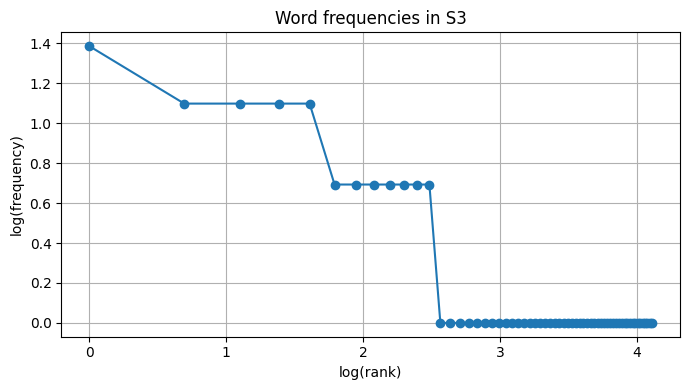

In [19]:
# Q5(b)(ii)
import math
import matplotlib.pyplot as plt

frequencies = Counter(S3).most_common()
log_ranks = []
log_frequencies = []

for rank, item in enumerate(frequencies, start=1):
    log_ranks.append(math.log(rank))
    log_frequencies.append(math.log(item[1]))

plt.figure(figsize=(7, 4))
plt.plot(log_ranks, log_frequencies, "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Word frequencies in S3")
plt.grid(True)
plt.tight_layout()
plt.show()


In [20]:
# Q5(b)(iii)
from nltk import bigrams

S1_bigrams = []
S3_bigrams = []

for result in processed_tickets:
    S1_bigrams.extend(bigrams(result["tokens"]))
    S3_bigrams.extend(bigrams(result["final"]))

print("Top 5 bigrams of S1:", Counter(S1_bigrams).most_common(5))
print("Top 5 bigrams of S3:", Counter(S3_bigrams).most_common(5))
print("Bigrams are counted within each ticket.")


Top 5 bigrams of S1: [(('.', 'please'), 4), (('please', 'help'), 3), (('help', '.'), 3), (('during', 'the'), 2), (('the', 'lab'), 2)]
Top 5 bigrams of S3: [(('please', 'help'), 3), (('lab', 'please'), 2), (('works', 'another'), 2), (('another', 'computer'), 2), (('call', '+91'), 1)]
Bigrams are counted within each ticket.


**Observe:** Why does TTR change from S1 to S4 in your data?

TTR is unique tokens divided by total tokens. It rises from 91/158 = 0.5759 in S1 to 61/79 = 0.7722 in S3 because punctuation and common stopwords are removed. Porter stemming merges related forms, so S4 has 59 unique tokens out of 79 and TTR = 0.7468. S4 is lower than S3 but higher than S1.


## Q6. Interpretation


(a) Why does TTR change from S1 to S4 in your dataset?


In [21]:
# Q6(a)
for name, tokens in zip(["S1", "S2", "S3", "S4"], [S1, S2, S3, S4]):
    print(name, "TTR:", round(len(set(tokens)) / len(tokens), 4))

print("Removing repeated punctuation and stopwords changes both the total and unique counts.")
print("In this dataset, TTR rises from S1 to S3 because many repeated tokens are removed.")
print("Porter stemming merges works and working into work.")
print("S3 and S4 have the same total, but S4 has fewer unique tokens, so its TTR is lower.")


S1 TTR: 0.5759
S2 TTR: 0.6439
S3 TTR: 0.7722
S4 TTR: 0.7468
Removing repeated punctuation and stopwords changes both the total and unique counts.
In this dataset, TTR rises from S1 to S3 because many repeated tokens are removed.
Porter stemming merges works and working into work.
S3 and S4 have the same total, but S4 has fewer unique tokens, so its TTR is lower.


(b) Give one example where word_tokenize() and your tokenizer differ. Explain the difference.


In [22]:
# Q6(b)
example = df.loc[1, "Ticket_Text"]
print("Text:", example)
print("Custom:", my_tokenize(example))
print("NLTK:", word_tokenize(example))
print("The custom tokenizer keeps isn't as one word; NLTK splits it into is and n't.")


Text: The printer won't print; it isn't jammed.
Custom: ['The', 'printer', "won't", 'print', ';', 'it', "isn't", 'jammed', '.']
NLTK: ['The', 'printer', 'wo', "n't", 'print', ';', 'it', 'is', "n't", 'jammed', '.']
The custom tokenizer keeps isn't as one word; NLTK splits it into is and n't.


(c) Give one example where stemming produces an undesirable result.


In [23]:
# Q6(c)
word = "computer"
print("Original word:", word)
print("Porter stem:", porter.stem(word))
print("Computer becomes comput, which is not a complete English word.")


Original word: computer
Porter stem: comput
Computer becomes comput, which is not a complete English word.


(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.


In [24]:
# Q6(d)
display(stem_table[stem_table["Word"] == "printer"])
print("In the tickets, printer is a noun meaning a device.")
print("POS-aware lemmatization keeps printer, while Lancaster changes it to print.")
print("Keeping printer preserves the device meaning.")


,Word,POS,Porter,Lancaster,Regexp,Lemma
13,printer,NN,printer,print,printer,printer


In the tickets, printer is a noun meaning a device.
POS-aware lemmatization keeps printer, while Lancaster changes it to print.
Keeping printer preserves the device meaning.
